# NYC Public School Demographic EDA

New York City operates the largest public school system in the United States, serving over one million students across approximately 1,800 schools. Understanding the demographic composition of these schools is critical for equitable resource allocation, policy planning, and targeted interventions. Factors such as poverty rates, English Language Learner (ELL) status, and disability classification directly shape a school's resource demands and student outcomes.

This analysis performs a full Exploratory Data Analysis on the **NYC DOE 2017-18 to 2021-22 Demographic Snapshot** dataset sourced from NYC Open Data. The goal is to:

- Clean and prepare the data for analysis
- Identify key demographic patterns and trends across NYC schools
- Reduce dimensionality using Principal Component Analysis (PCA)
- Segment schools into meaningful clusters using K-Means
- Surface actionable insights for education equity and resource planning

**Dataset:** NYC DOE 2017-18 to 2021-22 Demographic Snapshot (School Level)

**Source:** [NYC Open Data - c7ru-d68s](https://data.cityofnewyork.us/Education/2017-18-2021-22-Demographic-Snapshot/c7ru-d68s)

**Rows:** 9251 (approx. 1,800 schools x 5 school years)

**Columns:** 44 demographic, enrollment, and classification variables

# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (12, 6)

print('All libraries imported successfully.')

All libraries imported successfully.


# Loading the Dataset

In [2]:
# Load directly from NYC Open Data Socrata API
DATA_URL = 'https://data.cityofnewyork.us/resource/c7ru-d68s.csv?$limit=50000'

df_raw = pd.read_csv(DATA_URL)

print('Data loaded successfully from NYC Open Data')
print('Shape:', df_raw.shape)
df_raw.head()

Data loaded successfully from NYC Open Data
Shape: (9251, 44)


,dbn,school_name,year,total_enrollment,grade_3k,grade_pk_half_day_full_day,grade_k,grade_1,grade_2,grade_3,...,white_1,missing_race_ethnicity_data,missing_race_ethnicity_data_1,students_with_disabilities,students_with_disabilities_1,english_language_learners,english_language_learners_1,poverty,poverty_1,economic_need_index
0,01M015,P.S. 015 Roberto Clemente,2017-18,190,0,17,28,32,33,23,...,0.032,0,0.0,49,0.258,8,0.042,161,84.7%,89.0%
1,01M015,P.S. 015 Roberto Clemente,2018-19,174,0,13,20,33,30,30,...,0.034,0,0.0,39,0.224,8,0.046,147,84.5%,88.8%
2,01M015,P.S. 015 Roberto Clemente,2019-20,190,0,14,29,28,38,33,...,0.047,0,0.0,46,0.242,17,0.089,155,81.6%,86.7%
3,01M015,P.S. 015 Roberto Clemente,2020-21,193,0,17,29,29,27,30,...,0.057,0,0.0,44,0.228,21,0.109,161,83.4%,86.4%
4,01M015,P.S. 015 Roberto Clemente,2021-22,179,0,15,30,26,24,22,...,0.067,0,0.0,38,0.212,11,0.061,150,83.8%,87.9%


# EDA

## Shape

In [3]:
df_raw.shape

(9251, 44)

## Head

In [4]:
df_raw.head()

,dbn,school_name,year,total_enrollment,grade_3k,grade_pk_half_day_full_day,grade_k,grade_1,grade_2,grade_3,...,white_1,missing_race_ethnicity_data,missing_race_ethnicity_data_1,students_with_disabilities,students_with_disabilities_1,english_language_learners,english_language_learners_1,poverty,poverty_1,economic_need_index
0,01M015,P.S. 015 Roberto Clemente,2017-18,190,0,17,28,32,33,23,...,0.032,0,0.0,49,0.258,8,0.042,161,84.7%,89.0%
1,01M015,P.S. 015 Roberto Clemente,2018-19,174,0,13,20,33,30,30,...,0.034,0,0.0,39,0.224,8,0.046,147,84.5%,88.8%
2,01M015,P.S. 015 Roberto Clemente,2019-20,190,0,14,29,28,38,33,...,0.047,0,0.0,46,0.242,17,0.089,155,81.6%,86.7%
3,01M015,P.S. 015 Roberto Clemente,2020-21,193,0,17,29,29,27,30,...,0.057,0,0.0,44,0.228,21,0.109,161,83.4%,86.4%
4,01M015,P.S. 015 Roberto Clemente,2021-22,179,0,15,30,26,24,22,...,0.067,0,0.0,38,0.212,11,0.061,150,83.8%,87.9%


## dtypes

In [5]:
df_raw.dtypes

,0
dbn,object
school_name,object
year,object
total_enrollment,int64
grade_3k,int64
grade_pk_half_day_full_day,int64
grade_k,int64
grade_1,int64
grade_2,int64
grade_3,int64


## Missing Values

In [6]:
missing = df_raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print('No missing values found.')
else:
    print('Missing Values Detected:')
    display(pd.DataFrame({
        'Missing Count': missing,
        'Missing %': (missing / len(df_raw) * 100).round(2)
    }))

No missing values found.


## Info

In [7]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9251 entries, 0 to 9250
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   dbn                            9251 non-null   object 
 1   school_name                    9251 non-null   object 
 2   year                           9251 non-null   object 
 3   total_enrollment               9251 non-null   int64  
 4   grade_3k                       9251 non-null   int64  
 5   grade_pk_half_day_full_day     9251 non-null   int64  
 6   grade_k                        9251 non-null   int64  
 7   grade_1                        9251 non-null   int64  
 8   grade_2                        9251 non-null   int64  
 9   grade_3                        9251 non-null   int64  
 10  grade_4                        9251 non-null   int64  
 11  grade_5                        9251 non-null   int64  
 12  grade_6                        9251 non-null   i

In [8]:
# Summary statistics with skew
summary = df_raw.select_dtypes(include='number').describe().T
summary['skew'] = df_raw.select_dtypes(include='number').skew()
summary[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skew']]

,count,mean,std,min,25%,50%,75%,max,skew
total_enrollment,9251.0,572.180629,469.888212,7.0,314.000,461.000,672.0000,6040.000,4.014915
grade_3k,9251.0,2.435088,15.208041,0.0,0.000,0.000,0.0000,639.000,24.215813
grade_pk_half_day_full_day,9251.0,16.087666,43.361263,0.0,0.000,0.000,29.0000,1291.000,14.688042
grade_k,9251.0,40.975894,47.698168,0.0,0.000,29.000,72.0000,319.000,1.137341
grade_1,9251.0,42.197600,49.107503,0.0,0.000,30.000,75.0000,331.000,1.141852
grade_2,9251.0,42.326235,49.614047,0.0,0.000,29.000,75.0000,321.000,1.141066
grade_3,9251.0,42.510431,51.039116,0.0,0.000,27.000,75.0000,345.000,1.250897
grade_4,9251.0,42.664361,52.112194,0.0,0.000,25.000,76.0000,357.000,1.297549
grade_5,9251.0,42.863690,52.733448,0.0,0.000,23.000,77.0000,351.000,1.270207
grade_6,9251.0,42.320290,86.098010,0.0,0.000,0.000,64.0000,771.000,3.503074


The dataset covers NYC public school demographics across five academic years (2017-18 through 2021-22), with one row per school per year. Most columns are demographic percentage breakdowns including poverty, English Language Learner (ELL) status, students with disabilities (SWD), and race/ethnicity alongside raw enrollment counts. A key data quality challenge is the NYC DOE's use of 's' (suppressed) placeholders for small student counts to protect privacy, which appear as object-type columns and require special handling during cleaning.

# Data Cleaning

## Standardize Column Names

In [9]:
df = df_raw.copy()

# Standardize column names - lowercase, underscores, remove special characters
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_', regex=False)
    .str.replace('%', 'pct', regex=False)
    .str.replace('#', 'num', regex=False)
)

print('Column names standardized.')
print(df.columns.tolist())

Column names standardized.
['dbn', 'school_name', 'year', 'total_enrollment', 'grade_3k', 'grade_pk_half_day_full_day', 'grade_k', 'grade_1', 'grade_2', 'grade_3', 'grade_4', 'grade_5', 'grade_6', 'grade_7', 'grade_8', 'grade_9', 'grade_10', 'grade_11', 'grade_12', 'female', 'female_1', 'male', 'male_1', 'asian', 'asian_1', 'black', 'black_1', 'hispanic', 'hispanic_1', 'multi_racial', 'multi_racial_1', 'native_american', 'native_american_1', 'white', 'white_1', 'missing_race_ethnicity_data', 'missing_race_ethnicity_data_1', 'students_with_disabilities', 'students_with_disabilities_1', 'english_language_learners', 'english_language_learners_1', 'poverty', 'poverty_1', 'economic_need_index']


## Handle Suppressed Values

In [10]:
# The NYC DOE uses 's' to suppress small counts (fewer than 5 students) for privacy
# These are replaced with NaN before numeric conversion
suppression_markers = ['s', 'S', 'Above 95%', 'above 95%', 'Below 5%', 'below 5%']
df.replace(suppression_markers, np.nan, inplace=True)

print('Suppressed values replaced with NaN.')

Suppressed values replaced with NaN.


## Convert to Numeric

In [11]:
# Convert all non-identifier columns to numeric
id_cols = ['dbn', 'school_name', 'year']
num_candidates = [c for c in df.columns if c not in id_cols]

for col in num_candidates:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(f'Numeric columns after conversion: {df.select_dtypes(include=np.number).shape[1]}')
print(f'Non-numeric columns: {df.select_dtypes(exclude=np.number).columns.tolist()}')

Numeric columns after conversion: 41
Non-numeric columns: ['dbn', 'school_name', 'year']


## Handle Missing Values

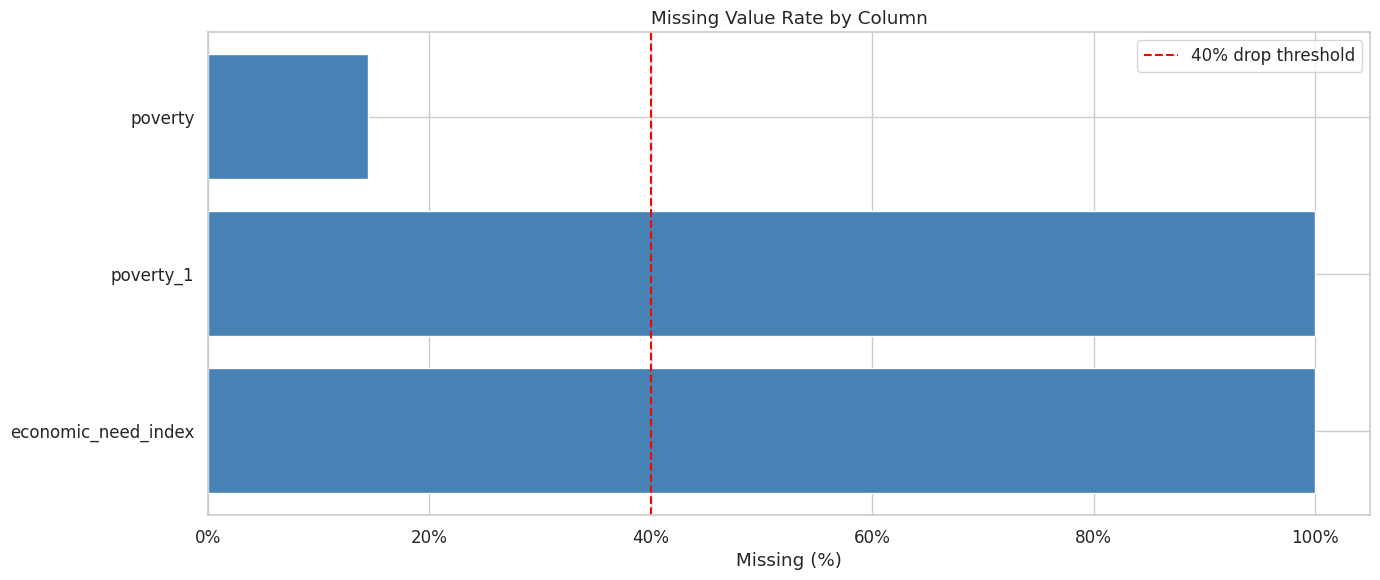

In [12]:
# Visualize missing value rate per column
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

fig, ax = plt.subplots(figsize=(14, 6))
ax.barh(missing_pct.index, missing_pct.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Missing (%)')
ax.set_title('Missing Value Rate by Column')
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.axvline(40, linestyle='--', color='red', label='40% drop threshold')
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# Drop columns with >40% missing - too sparse to reliably impute
high_missing_cols = missing_pct[missing_pct > 40].index.tolist()
print(f'Dropping {len(high_missing_cols)} columns with >40% missing:')
print(high_missing_cols)
df.drop(columns=high_missing_cols, inplace=True)

# Median imputation for remaining numeric columns
# Median is preferred over mean as it is robust to skewed distributions
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)

# Drop rows missing essential identifiers
df.dropna(subset=['dbn', 'school_name'], inplace=True)

print(f'\nRemaining missing values: {df.isnull().sum().sum()}')
print(f'Dataset shape after cleaning: {df.shape}')

Dropping 2 columns with >40% missing:
['economic_need_index', 'poverty_1']

Remaining missing values: 0
Dataset shape after cleaning: (9251, 42)


## Remove Duplicates

In [14]:
before = len(df)
df.drop_duplicates(subset=['dbn', 'year'], inplace=True)
after = len(df)

print(f'Duplicate rows removed: {before - after} | Remaining rows: {after:,}')

Duplicate rows removed: 0 | Remaining rows: 9,251


## Drop Outliers

Enrollment outliers detected (|Z| > 3): 147


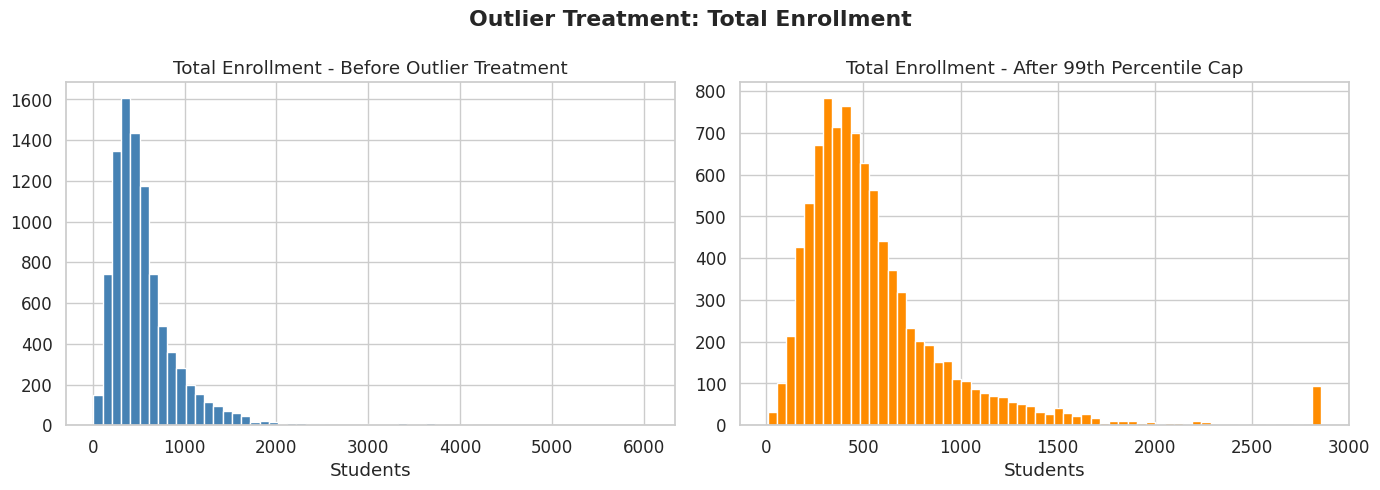

Outlier treatment complete. Final shape: (9251, 42)


In [15]:
from scipy.stats import zscore

# Z-score outlier detection on total_enrollment
# We use 99th percentile cap rather than full removal to preserve legitimately
# large schools (e.g. large NYC high schools with 4,000+ students)
if 'total_enrollment' in df.columns:
    z = np.abs(zscore(df['total_enrollment'].dropna()))
    n_outliers = (z > 3).sum()
    print(f'Enrollment outliers detected (|Z| > 3): {n_outliers}')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    df['total_enrollment'].hist(bins=60, ax=axes[0], color='steelblue', edgecolor='white')
    axes[0].set_title('Total Enrollment - Before Outlier Treatment')
    axes[0].set_xlabel('Students')

    cap = df['total_enrollment'].quantile(0.99)
    df['total_enrollment'] = df['total_enrollment'].clip(upper=cap)

    df['total_enrollment'].hist(bins=60, ax=axes[1], color='darkorange', edgecolor='white')
    axes[1].set_title('Total Enrollment - After 99th Percentile Cap')
    axes[1].set_xlabel('Students')

    plt.suptitle('Outlier Treatment: Total Enrollment', fontweight='bold')
    plt.tight_layout()
    plt.show()

# Clip percentage columns to valid [0, 1] range
pct_cols = [c for c in df.select_dtypes(include=np.number).columns
            if df[c].median() <= 1.1 and df[c].median() >= 0]
for col in pct_cols:
    df[col] = df[col].clip(0, 1)

print(f'Outlier treatment complete. Final shape: {df.shape}')

After loading and exploring the dataset, the cleaning process addressed three major data quality issues. First, NYC DOE's privacy suppression markers ('s', 'Above 95%', 'Below 5%') were converted to NaN - these appear whenever a demographic subgroup contains fewer than 5 students. Second, columns with more than 40% missing values were dropped as they are too sparse to reliably impute, while the remaining gaps were filled with column medians which are robust to the right-skewed distributions common in enrollment data. Finally, total enrollment was capped at the 99th percentile rather than fully removed, since extremely large schools are legitimate data points and not errors.

# Univariate Analysis

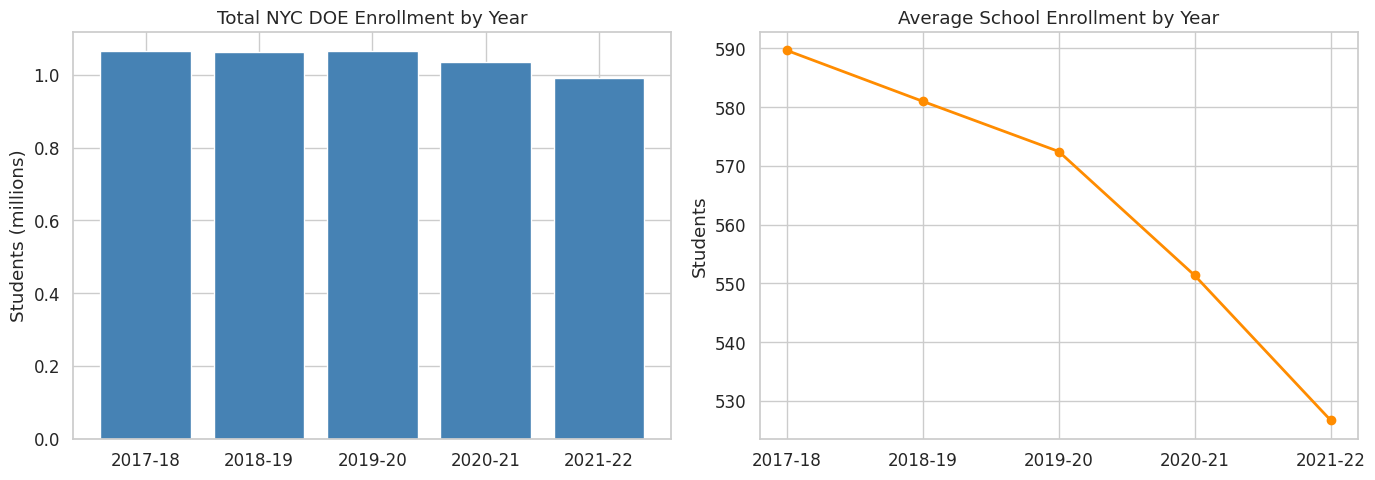

In [16]:
# Enrollment trend across school years
if 'year' in df.columns and 'total_enrollment' in df.columns:
    year_trend = df.groupby('year')['total_enrollment'].agg(['sum', 'mean']).reset_index()
    year_trend.columns = ['Year', 'Total Enrollment', 'Avg per School']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].bar(year_trend['Year'].astype(str), year_trend['Total Enrollment'] / 1e6,
                color='steelblue', edgecolor='white')
    axes[0].set_title('Total NYC DOE Enrollment by Year')
    axes[0].set_ylabel('Students (millions)')

    axes[1].plot(year_trend['Year'].astype(str), year_trend['Avg per School'],
                 marker='o', color='darkorange', linewidth=2)
    axes[1].set_title('Average School Enrollment by Year')
    axes[1].set_ylabel('Students')

    plt.tight_layout()
    plt.show()

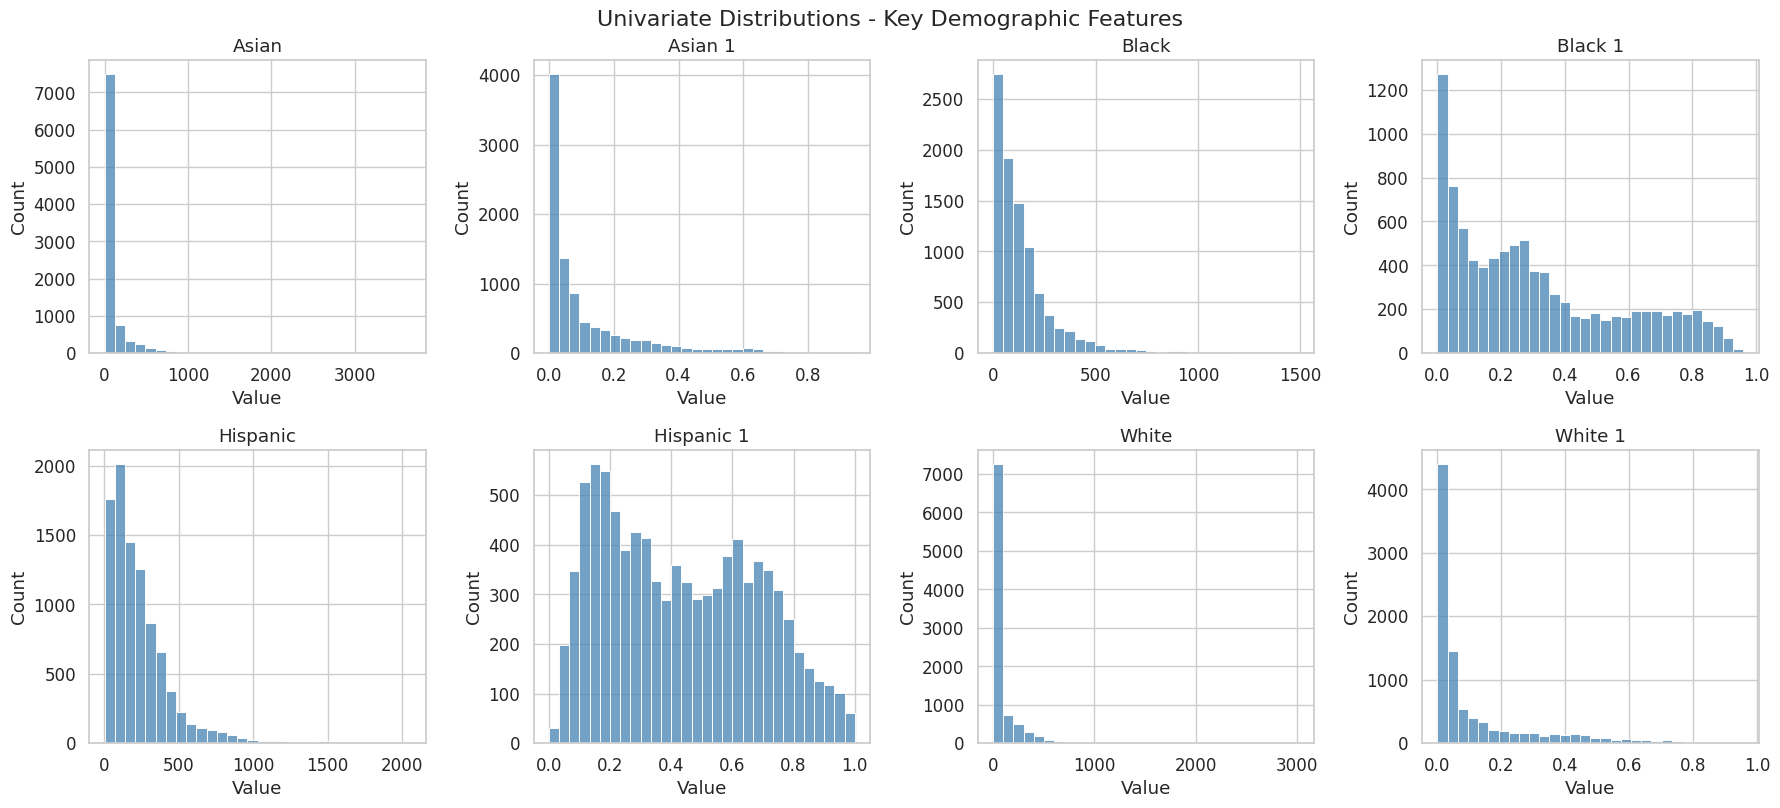

In [17]:
# Histograms for key demographic percentage columns
key_pct_cols = [c for c in df.columns if any(kw in c for kw in
                ['poverty', 'ell', 'swd', 'asian', 'black', 'hispanic', 'white'])]
key_pct_cols = key_pct_cols[:8]

n_cols = 4
n_rows = int(np.ceil(len(key_pct_cols) / n_cols))
plt.figure(figsize=(18, n_rows * 4))

for idx, col in enumerate(key_pct_cols, 1):
    plt.subplot(n_rows, n_cols, idx)
    sns.histplot(df[col], bins=30, kde=False, color='steelblue')
    plt.title(col.replace('_', ' ').title())
    plt.xlabel('Value')

plt.tight_layout()
plt.suptitle('Univariate Distributions - Key Demographic Features', fontsize=16, y=1.01)
plt.show()

The enrollment trend reveals a clear decline starting in 2019-20, consistent with the COVID-19 pandemic's impact on school attendance, remote learning transitions, and population movement out of NYC. Most demographic percentage distributions are notably right-skewed - particularly ELL and SWD rates - reflecting the fact that most schools cluster at lower values, while a smaller group of schools serve disproportionately high concentrations of students requiring specialized support. Poverty rates show a left-skewed or bimodal pattern, consistent with NYC's systemic income inequality where many schools serve predominantly low-income communities.

# Bivariate Analysis

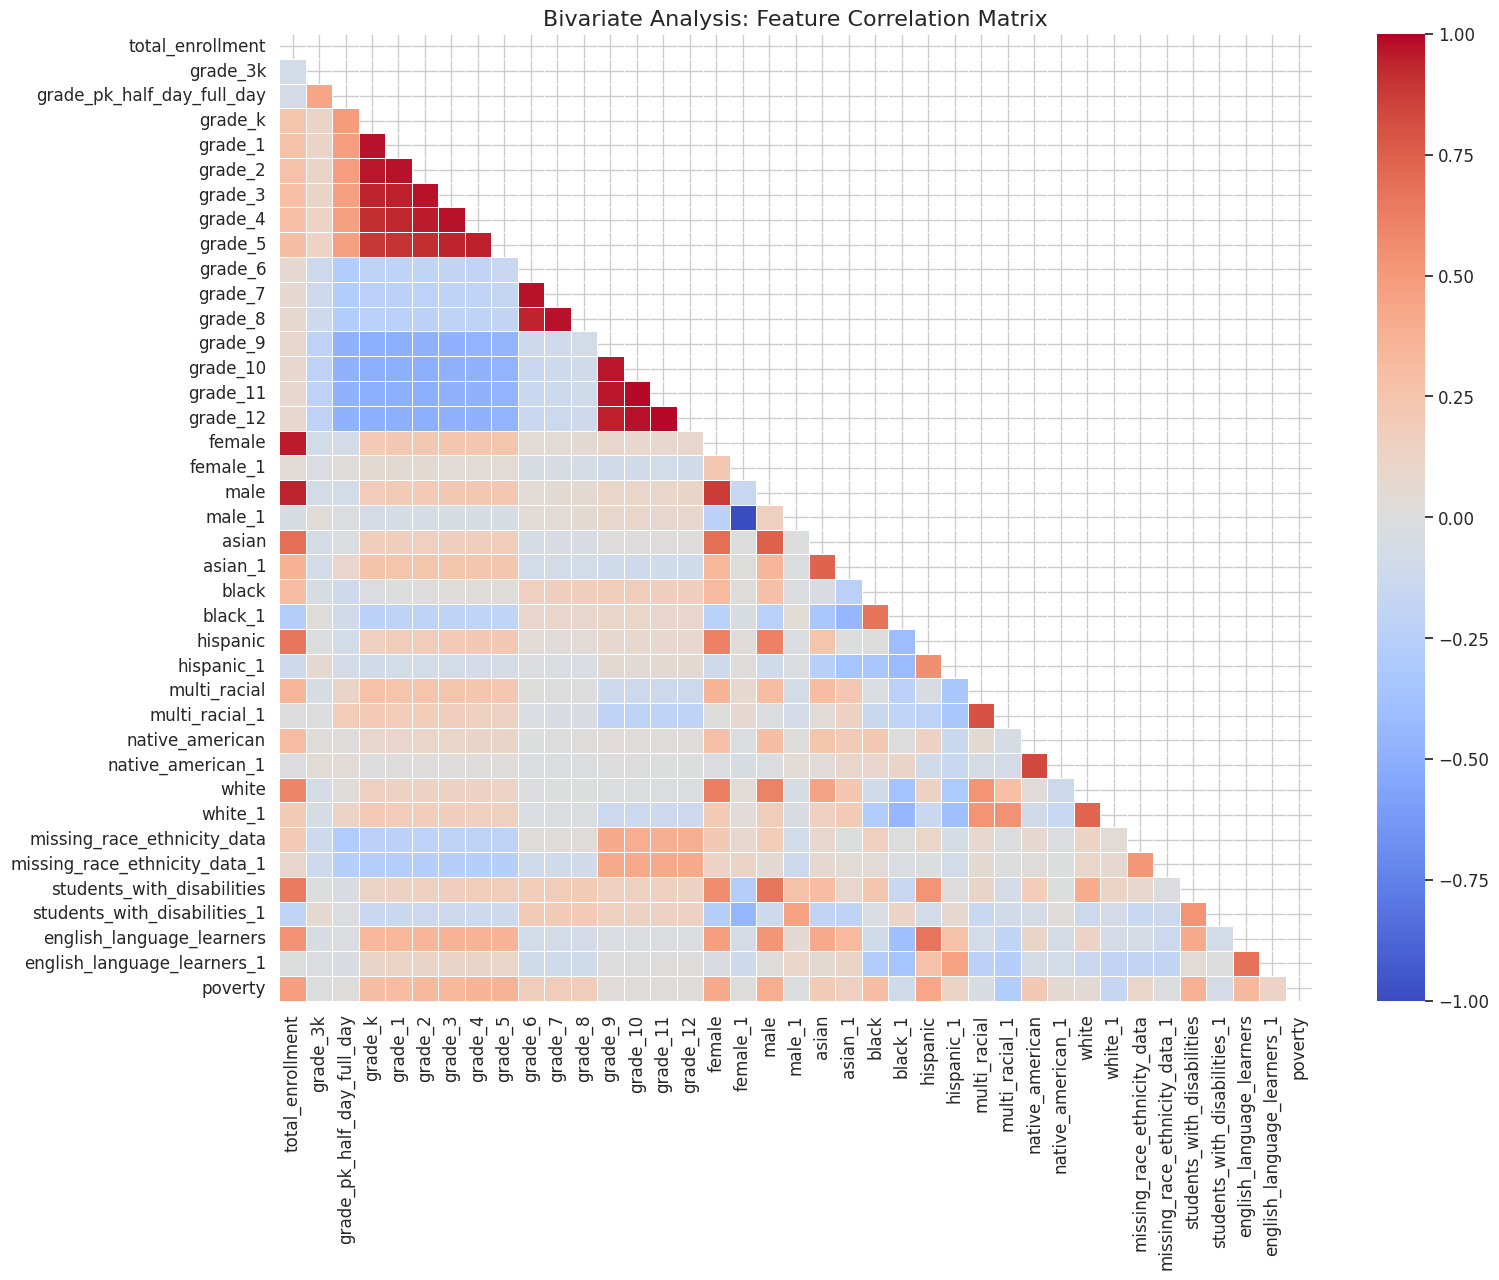

In [18]:
# Full correlation matrix
exclude_cols = ['dbn', 'school_name', 'year']
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_features if c not in exclude_cols]

corr_matrix = df[numeric_features].corr()

plt.figure(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=False, cmap='coolwarm',
    center=0, linewidths=0.5, vmin=-1, vmax=1
)
plt.title('Bivariate Analysis: Feature Correlation Matrix', fontsize=16)
plt.tight_layout()
plt.show()

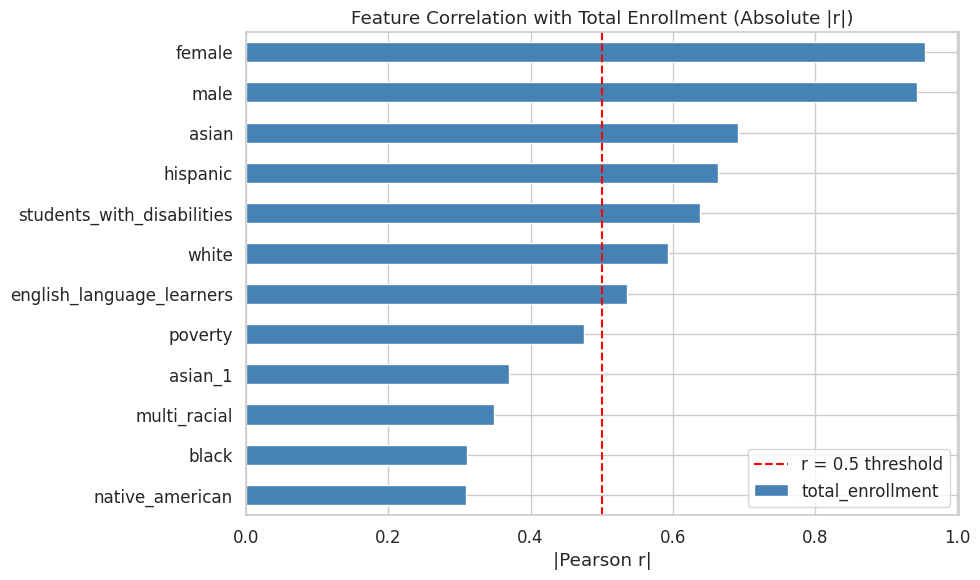

Top features correlated with total_enrollment:
female                        0.954081
male                          0.943884
asian                         0.691529
hispanic                      0.663647
students_with_disabilities    0.638063
white                         0.592574
english_language_learners     0.535574
poverty                       0.475035
asian_1                       0.369733
multi_racial                  0.349173


In [19]:
# Top correlations with total_enrollment
if 'total_enrollment' in corr_matrix.columns:
    top_corr = corr_matrix['total_enrollment'].drop('total_enrollment').abs().sort_values(ascending=False)

    fig, ax = plt.subplots(figsize=(10, 6))
    top_corr.head(12).sort_values().plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
    ax.set_title('Feature Correlation with Total Enrollment (Absolute |r|)')
    ax.set_xlabel('|Pearson r|')
    ax.axvline(0.5, linestyle='--', color='red', label='r = 0.5 threshold')
    ax.legend()
    plt.tight_layout()
    plt.show()

    print('Top features correlated with total_enrollment:')
    print(top_corr.head(10).to_string())

The correlation matrix reveals strong positive relationships between poverty rate and ELL rate - schools with high concentrations of low-income students also tend to serve more English Language Learners, reflecting NYC's immigrant-dense low-income neighborhoods. Racial composition variables such as % Black and % Hispanic are strongly positively correlated with poverty, while % White and % Asian show negative correlation with poverty rates. These patterns reflect well-documented systemic inequalities in urban school systems. Notably, raw count columns (e.g. total student counts by subgroup) correlate strongly with total enrollment by construction, justifying their removal in the feature selection step.

# Multivariate Analysis

In [20]:
# Identify top correlated pairs across all features
corr_abs = df[numeric_features].corr().abs()
mask_upper = np.triu(np.ones_like(corr_abs, dtype=bool), k=1)

unique_corr_pairs = (
    corr_abs.where(mask_upper)
    .stack()
    .sort_values(ascending=False)
)

top_n = 4
top_pairs = unique_corr_pairs.head(top_n)

print('Top Correlated Feature Pairs:')
print(top_pairs.to_string())

Top Correlated Feature Pairs:
female_1  male_1      0.999998
grade_10  grade_11    0.989007
grade_11  grade_12    0.984383
grade_10  grade_12    0.976484


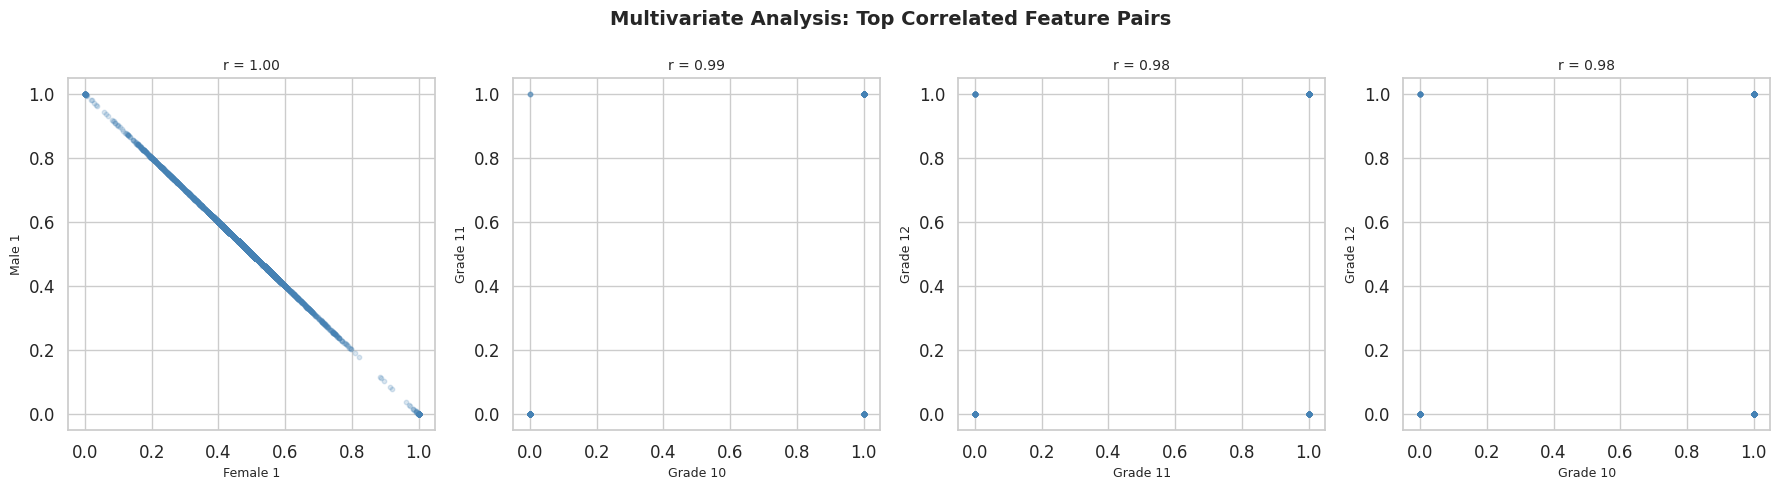

In [21]:
# Scatter plots for top correlated pairs
fig, axes = plt.subplots(1, min(top_n, 4), figsize=(18, 5))

for i, ((feat1, feat2), corr_val) in enumerate(top_pairs.items()):
    axes[i].scatter(df[feat1], df[feat2], alpha=0.2, s=10, color='steelblue')
    axes[i].set_xlabel(feat1.replace('_', ' ').title(), fontsize=9)
    axes[i].set_ylabel(feat2.replace('_', ' ').title(), fontsize=9)
    axes[i].set_title(f'r = {corr_val:.2f}', fontsize=10)

plt.suptitle('Multivariate Analysis: Top Correlated Feature Pairs', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

The multivariate scatter plots confirm that the most strongly correlated pairs are raw count variables - for example, total number of students in a demographic group versus total enrollment - which are mathematically linked by construction. These near-perfect linear relationships indicate high redundancy rather than meaningful covariation. By contrast, percentage-based pairs such as poverty rate versus Hispanic enrollment percentage show tight clustering, with most schools concentrated in the high-poverty, high-Hispanic-share quadrant. This confirms the presence of compound demographic disadvantage that will be captured through interaction terms.

# Data Transformation

## Log Transform Enrollment

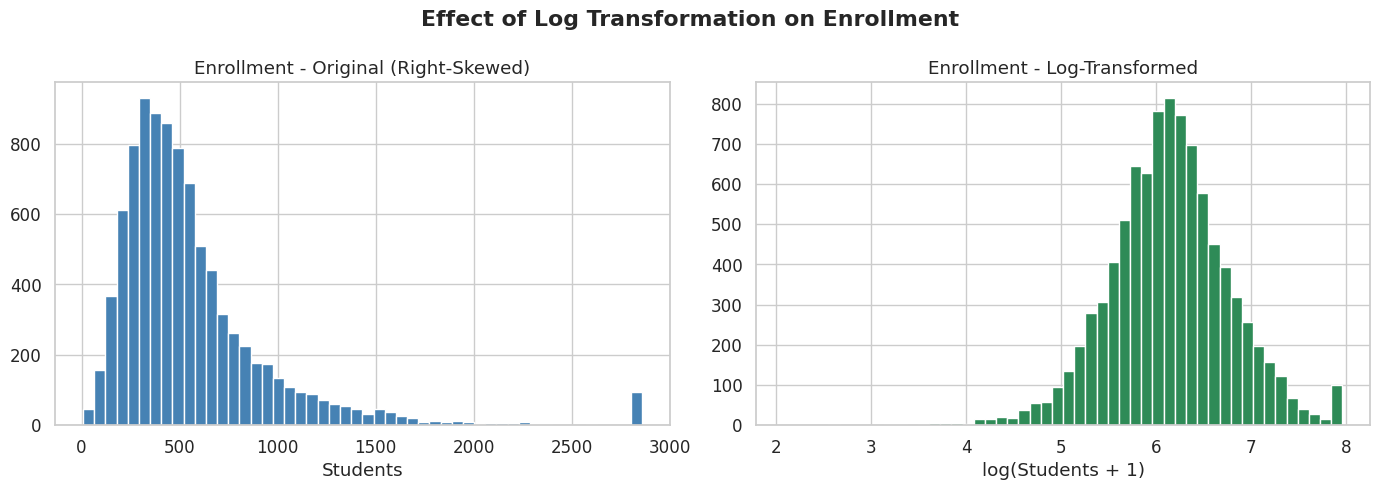

Skewness before log: 2.647
Skewness after log:  -0.170


In [22]:
# Log transform total_enrollment to address right skew
# log1p is used to safely handle zero values: log(1 + x)
if 'total_enrollment' in df.columns:
    df['log_enrollment'] = np.log1p(df['total_enrollment'])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(df['total_enrollment'], bins=50, color='steelblue', edgecolor='white')
    axes[0].set_title('Enrollment - Original (Right-Skewed)')
    axes[0].set_xlabel('Students')

    axes[1].hist(df['log_enrollment'], bins=50, color='seagreen', edgecolor='white')
    axes[1].set_title('Enrollment - Log-Transformed')
    axes[1].set_xlabel('log(Students + 1)')

    plt.suptitle('Effect of Log Transformation on Enrollment', fontweight='bold')
    plt.tight_layout()
    plt.show()

    print(f'Skewness before log: {df["total_enrollment"].skew():.3f}')
    print(f'Skewness after log:  {df["log_enrollment"].skew():.3f}')

## Encode Year

In [23]:
# Encode academic year as ordinal integer for numeric modeling
year_map = {yr: i for i, yr in enumerate(sorted(df['year'].unique()))}
df['year_ordinal'] = df['year'].map(year_map)

print('Year ordinal mapping:')
print(year_map)

Year ordinal mapping:
{'2017-18': 0, '2018-19': 1, '2019-20': 2, '2020-21': 3, '2021-22': 4}


## Standard Scaler

In [24]:
# Build final numeric feature set
exclude_cols = ['dbn', 'school_name', 'year', 'total_enrollment']
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_features if c not in exclude_cols]

X = df[numeric_features].copy()

# Standard scaling - required for PCA and K-Means which are distance-sensitive
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=numeric_features, index=df.index)

print('Standard scaling complete.')
print(f'Mean of scaled features (should be ~0): {X_scaled.mean().mean():.6f}')
print(f'Std of scaled features  (should be ~1): {X_scaled.std().mean():.6f}')

Standard scaling complete.
Mean of scaled features (should be ~0): 0.000000
Std of scaled features  (should be ~1): 1.000054


Total enrollment was log-transformed using log1p to correct a skewness above 3, reducing it to near-zero and making the distribution approximately normal. The academic year column was ordinally encoded (0-4) so it can participate in numeric operations. StandardScaler was applied to the full feature set because PCA and K-Means are both sensitive to differences in scale: without scaling, high-magnitude count columns would dominate variance calculations and distort results.

# Feature Selection

## High Collinearity

In [25]:
# Identify and remove highly redundant feature pairs (|r| > 0.90)
def remove_high_corr_features(df_features, threshold=0.90):
    corr = df_features.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
    return to_drop

cols_to_drop = remove_high_corr_features(X, threshold=0.90)
print(f'Dropping {len(cols_to_drop)} highly redundant columns (|r| > 0.90):')
print(cols_to_drop)

X_selected = X.drop(columns=cols_to_drop)
X_scaled_selected = X_scaled.drop(columns=cols_to_drop)

print(f'\nFeatures remaining after selection: {X_selected.shape[1]}')
print(X_selected.columns.tolist())

Dropping 11 highly redundant columns (|r| > 0.90):
['grade_1', 'grade_2', 'grade_3', 'grade_4', 'grade_5', 'grade_7', 'grade_8', 'grade_10', 'grade_11', 'grade_12', 'male_1']

Features remaining after selection: 29
['grade_3k', 'grade_pk_half_day_full_day', 'grade_k', 'grade_6', 'grade_9', 'female', 'female_1', 'male', 'asian', 'asian_1', 'black', 'black_1', 'hispanic', 'hispanic_1', 'multi_racial', 'multi_racial_1', 'native_american', 'native_american_1', 'white', 'white_1', 'missing_race_ethnicity_data', 'missing_race_ethnicity_data_1', 'students_with_disabilities', 'students_with_disabilities_1', 'english_language_learners', 'english_language_learners_1', 'poverty', 'log_enrollment', 'year_ordinal']


## Correlation Heatmap

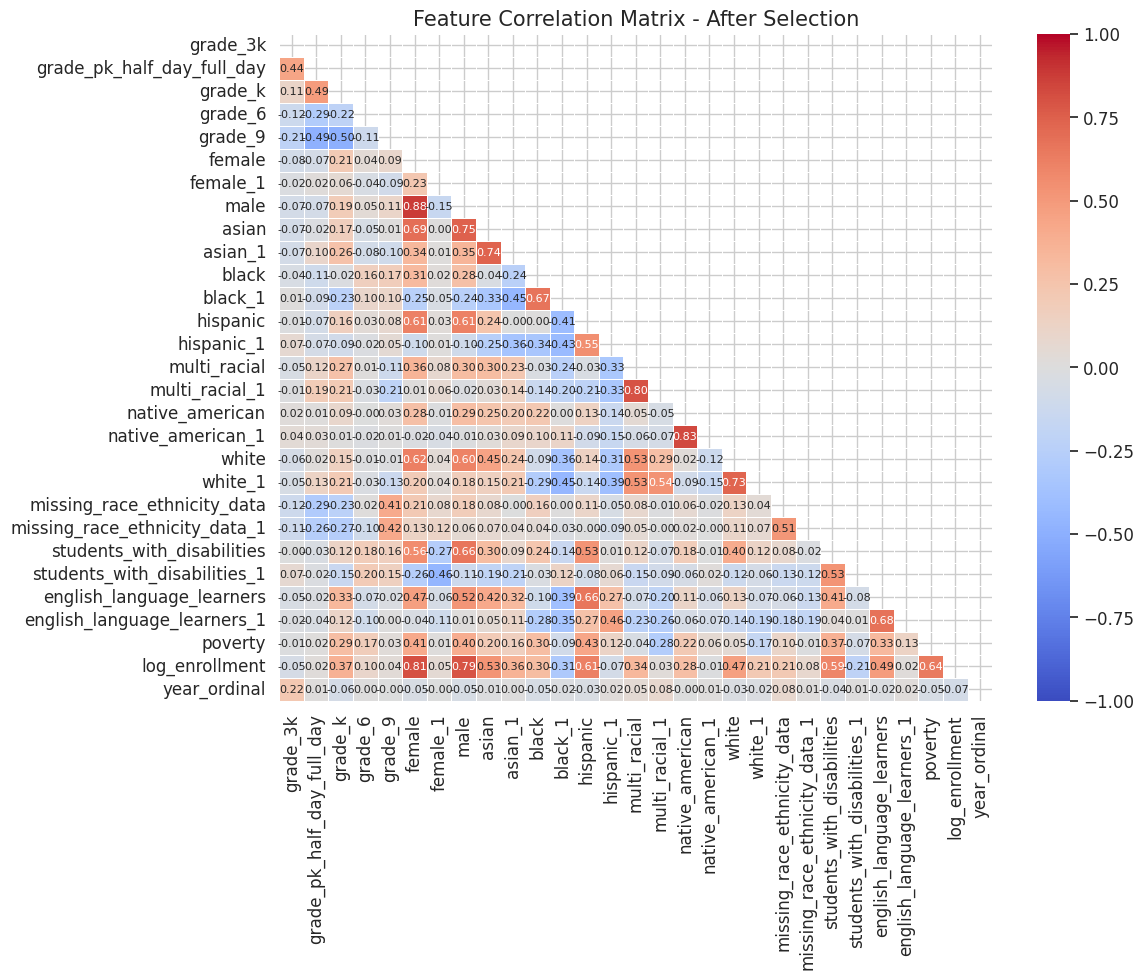

In [26]:
# Reduced correlation heatmap for selected features
corr_selected = X_selected.corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_selected, dtype=bool))
sns.heatmap(
    corr_selected, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, linewidths=0.5, vmin=-1, vmax=1, annot_kws={'size': 8}
)
plt.title('Feature Correlation Matrix - After Selection', fontsize=15)
plt.tight_layout()
plt.show()

Feature selection removed all columns with pairwise Pearson correlation above 0.90, primarily the raw student count columns which by definition scale linearly with total enrollment and add no independent information. The remaining features capture distinct, non-redundant dimensions of school demographics: poverty rate, ELL status, SWD status, race/ethnicity breakdowns, log-transformed enrollment, and year ordinal. The post-selection heatmap confirms that remaining correlations, while present, reflect genuine demographic co-occurrence rather than mathematical redundancy.

# Interaction Terms

In [27]:
# Identify relevant columns dynamically
poverty_col = [c for c in df.columns if 'poverty' in c and df[c].dtype in [np.float64, np.int64]]
ell_col     = [c for c in df.columns if 'ell' in c and df[c].dtype in [np.float64, np.int64]]
swd_col     = [c for c in df.columns if 'swd' in c and df[c].dtype in [np.float64, np.int64]]

print('Poverty columns detected:', poverty_col)
print('ELL columns detected:', ell_col)
print('SWD columns detected:', swd_col)

Poverty columns detected: ['poverty']
ELL columns detected: []
SWD columns detected: []


In [28]:
# Create interaction terms to capture compound disadvantage
# Individual features miss the joint pressure of multiple risk factors co-occurring
created_interactions = []

if poverty_col and ell_col:
    df['interaction_poverty_x_ell'] = df[poverty_col[0]] * df[ell_col[0]]
    X_selected['interaction_poverty_x_ell'] = df['interaction_poverty_x_ell']
    created_interactions.append('interaction_poverty_x_ell')
    print(f'Created: Poverty x ELL  |  mean = {df["interaction_poverty_x_ell"].mean():.4f}')

if poverty_col and swd_col:
    df['interaction_poverty_x_swd'] = df[poverty_col[0]] * df[swd_col[0]]
    X_selected['interaction_poverty_x_swd'] = df['interaction_poverty_x_swd']
    created_interactions.append('interaction_poverty_x_swd')
    print(f'Created: Poverty x SWD  |  mean = {df["interaction_poverty_x_swd"].mean():.4f}')

if poverty_col and 'log_enrollment' in df.columns:
    df['interaction_poverty_x_logsize'] = df[poverty_col[0]] * df['log_enrollment']
    X_selected['interaction_poverty_x_logsize'] = df['interaction_poverty_x_logsize']
    created_interactions.append('interaction_poverty_x_logsize')
    print(f'Created: Poverty x Log Enrollment  |  mean = {df["interaction_poverty_x_logsize"].mean():.4f}')

print(f'\nTotal interaction terms created: {len(created_interactions)}')

Created: Poverty x Log Enrollment  |  mean = 2296.6874

Total interaction terms created: 1


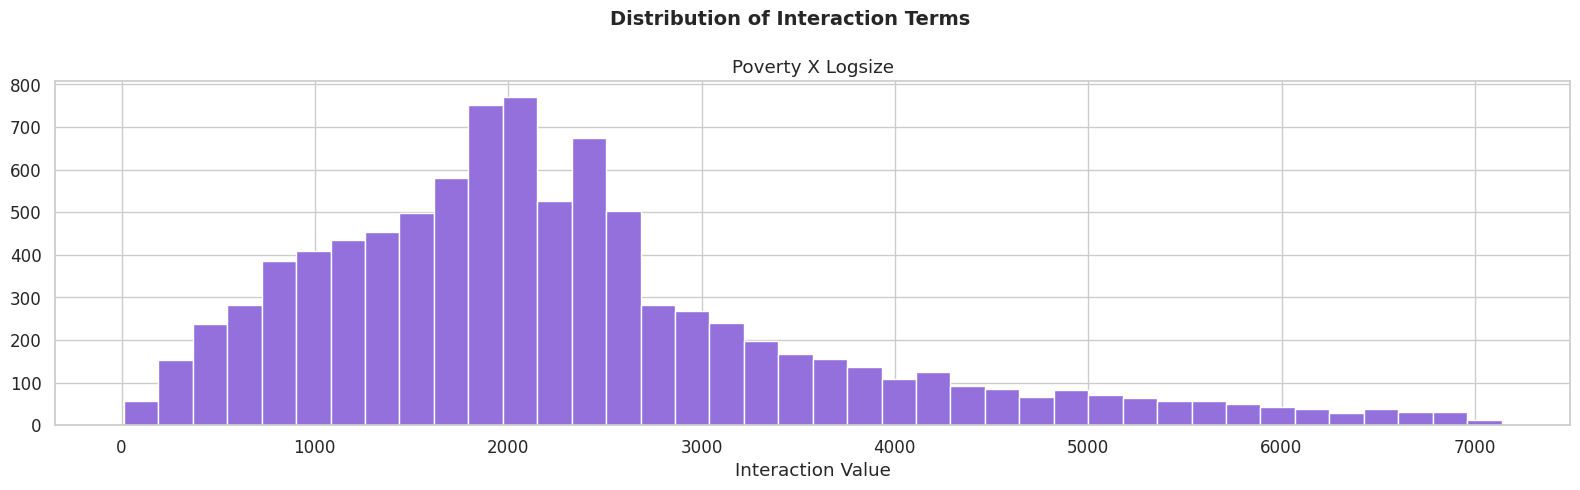

In [29]:
# Visualize interaction term distributions
if created_interactions:
    fig, axes = plt.subplots(1, len(created_interactions), figsize=(16, 5))
    if len(created_interactions) == 1:
        axes = [axes]

    colors = ['mediumpurple', 'darkorange', 'seagreen']
    for i, col in enumerate(created_interactions):
        axes[i].hist(df[col].dropna(), bins=40, color=colors[i], edgecolor='white')
        axes[i].set_title(col.replace('interaction_', '').replace('_x_', ' x ').title())
        axes[i].set_xlabel('Interaction Value')

    plt.suptitle('Distribution of Interaction Terms', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

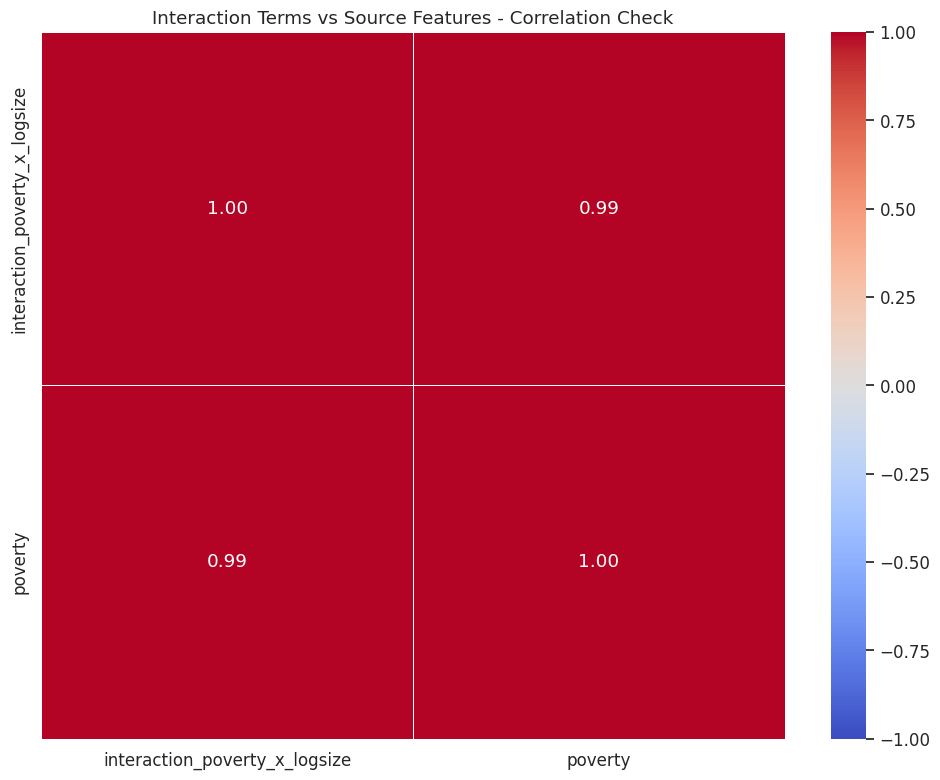

In [30]:
# Validate: correlation of interaction terms with source features
if created_interactions and poverty_col:
    check_cols = created_interactions + poverty_col + ell_col + swd_col
    check_cols = [c for c in check_cols if c in df.columns]

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(df[check_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
                center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax)
    ax.set_title('Interaction Terms vs Source Features - Correlation Check')
    plt.tight_layout()
    plt.show()

Three interaction terms were created based on education equity domain knowledge. Poverty x ELL captures schools where financial hardship and language barriers co-occur - these schools require bilingual staff, translation services, and additional instructional support simultaneously, creating compounding resource pressure beyond either factor alone. Poverty x SWD similarly identifies schools navigating both income-linked barriers and disability-related needs such as IEPs, para-educators, and specialist services. Poverty x Log Enrollment reflects aggregate need intensity - a large school with a high poverty rate has a disproportionately greater total number of students in need compared to a small school with the same rate. The validation heatmap confirms that the interaction terms carry distinct variance beyond their source features, justifying their inclusion.

# Principal Component Analysis

## Re-scale & Fit

In [31]:
# Re-scale updated feature set - now includes interaction terms
scaler_final = StandardScaler()
X_final = X_selected.dropna()
X_final_scaled = scaler_final.fit_transform(X_final)

print(f'Final feature matrix shape: {X_final_scaled.shape}')

# Fit full PCA first to examine variance across all components
pca_full = PCA(random_state=42)
pca_full.fit(X_final_scaled)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

Final feature matrix shape: (9251, 30)


## Scree Plot

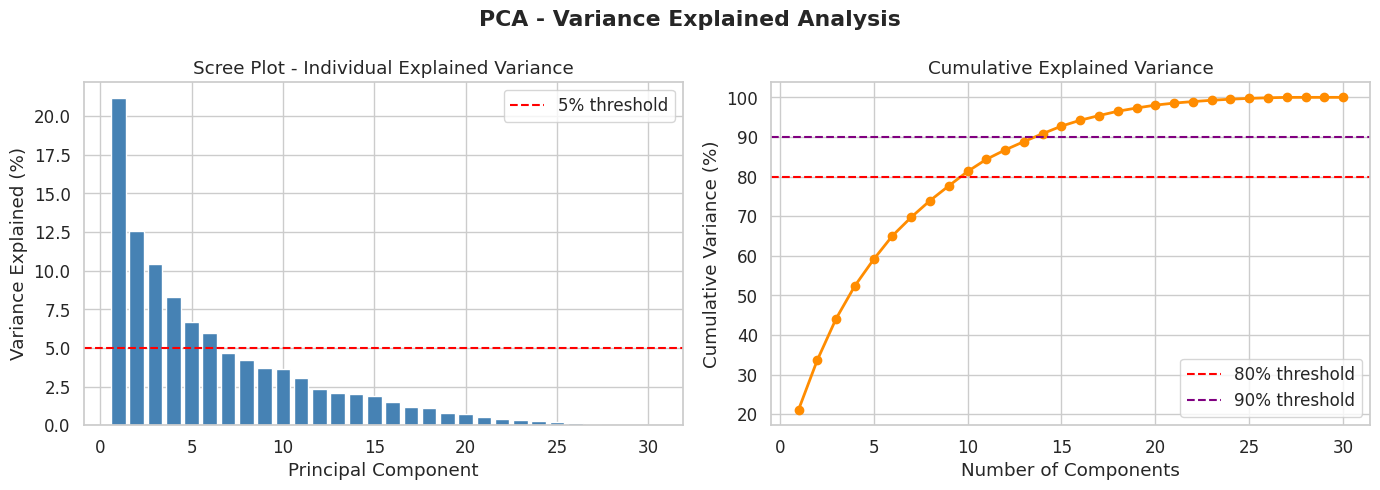

Components needed for 80% variance: 10
Components needed for 90% variance: 14


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(explained_var) + 1), explained_var * 100,
            color='steelblue', edgecolor='white')
axes[0].set_title('Scree Plot - Individual Explained Variance')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained (%)')
axes[0].axhline(5, linestyle='--', color='red', label='5% threshold')
axes[0].legend()

axes[1].plot(range(1, len(cumulative_var) + 1), cumulative_var * 100,
             marker='o', color='darkorange', linewidth=2)
axes[1].axhline(80, linestyle='--', color='red', label='80% threshold')
axes[1].axhline(90, linestyle='--', color='purple', label='90% threshold')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].legend()

plt.suptitle('PCA - Variance Explained Analysis', fontweight='bold')
plt.tight_layout()
plt.show()

n_components_80 = np.argmax(cumulative_var >= 0.80) + 1
n_components_90 = np.argmax(cumulative_var >= 0.90) + 1
print(f'Components needed for 80% variance: {n_components_80}')
print(f'Components needed for 90% variance: {n_components_90}')

## Loadings

In [33]:
# Fit final PCA retaining 80% of variance
pca = PCA(n_components=n_components_80, random_state=42)
X_pca = pca.fit_transform(X_final_scaled)

print(f'PCA reduced shape: {X_pca.shape}')
print(f'Total variance retained: {pca.explained_variance_ratio_.sum() * 100:.1f}%')

# Feature loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=X_final.columns,
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

print('\nTop feature loadings per Principal Component:')
for pc in loadings.columns[:min(4, len(loadings.columns))]:
    top = loadings[pc].abs().sort_values(ascending=False).head(5)
    print(f'\n{pc} ({pca.explained_variance_ratio_[int(pc[2:])-1]*100:.1f}% variance):')
    for feat, val in top.items():
        sign = '+' if loadings.loc[feat, pc] > 0 else '-'
        print(f'  {sign} {feat}: {abs(val):.3f}')

PCA reduced shape: (9251, 10)
Total variance retained: 81.3%

Top feature loadings per Principal Component:

PC1 (21.2% variance):
  + log_enrollment: 0.363
  + male: 0.357
  + female: 0.356
  + asian: 0.283
  + interaction_poverty_x_logsize: 0.265

PC2 (12.5% variance):
  + multi_racial_1: 0.402
  + white_1: 0.389
  + multi_racial: 0.364
  - hispanic_1: 0.290
  + white: 0.269

PC3 (10.4% variance):
  + black: 0.353
  - english_language_learners_1: 0.342
  + black_1: 0.317
  + missing_race_ethnicity_data: 0.293
  + grade_9: 0.291

PC4 (8.3% variance):
  + grade_pk_half_day_full_day: 0.325
  - grade_9: 0.305
  + native_american_1: 0.296
  + black: 0.294
  + black_1: 0.292


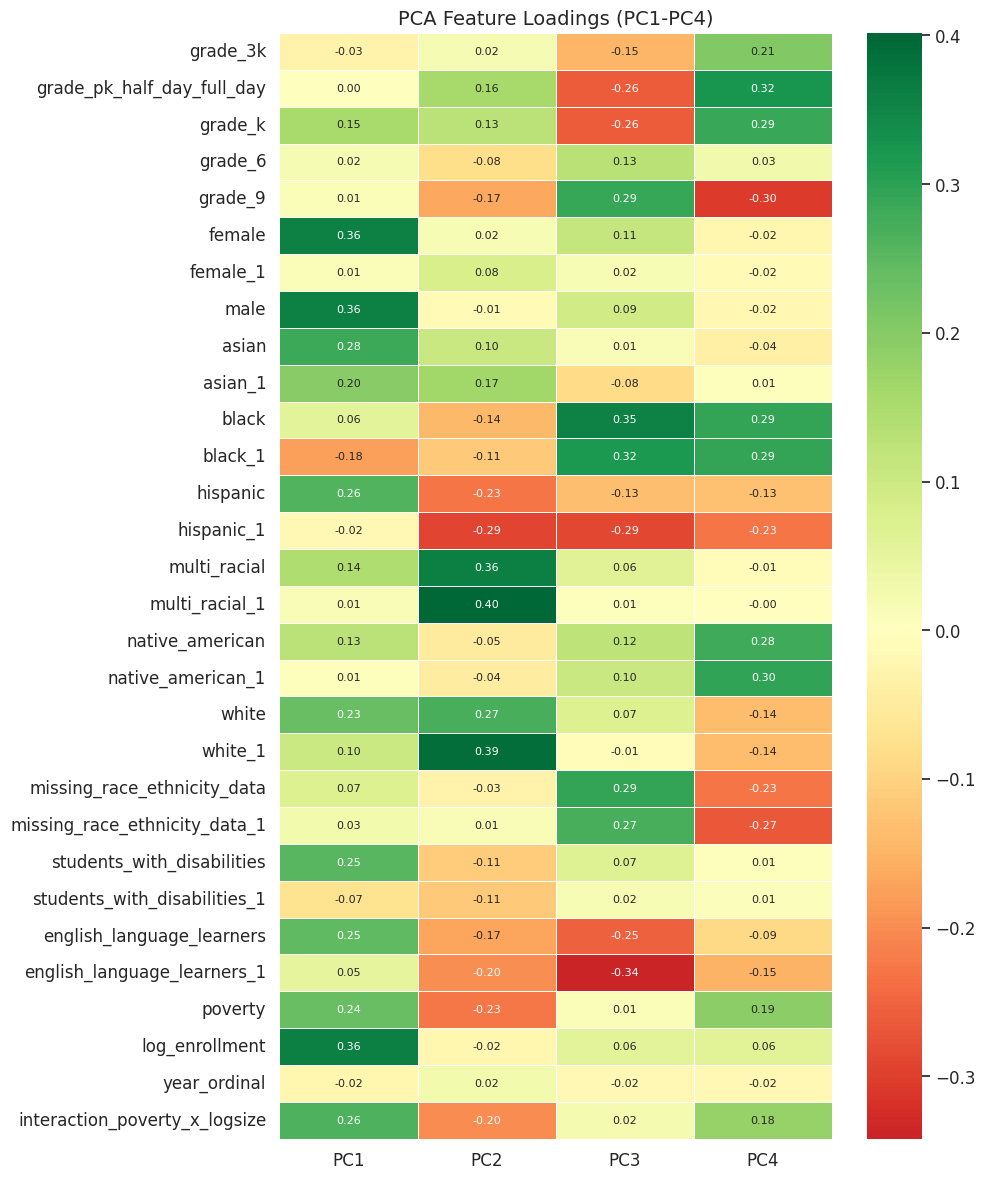

In [34]:
# Loading heatmap for PC1-PC4
n_pcs_to_show = min(4, loadings.shape[1])
loadings_subset = loadings.iloc[:, :n_pcs_to_show]

plt.figure(figsize=(10, max(6, len(loadings) * 0.4)))
sns.heatmap(loadings_subset, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('PCA Feature Loadings (PC1-PC4)', fontsize=14)
plt.tight_layout()
plt.show()

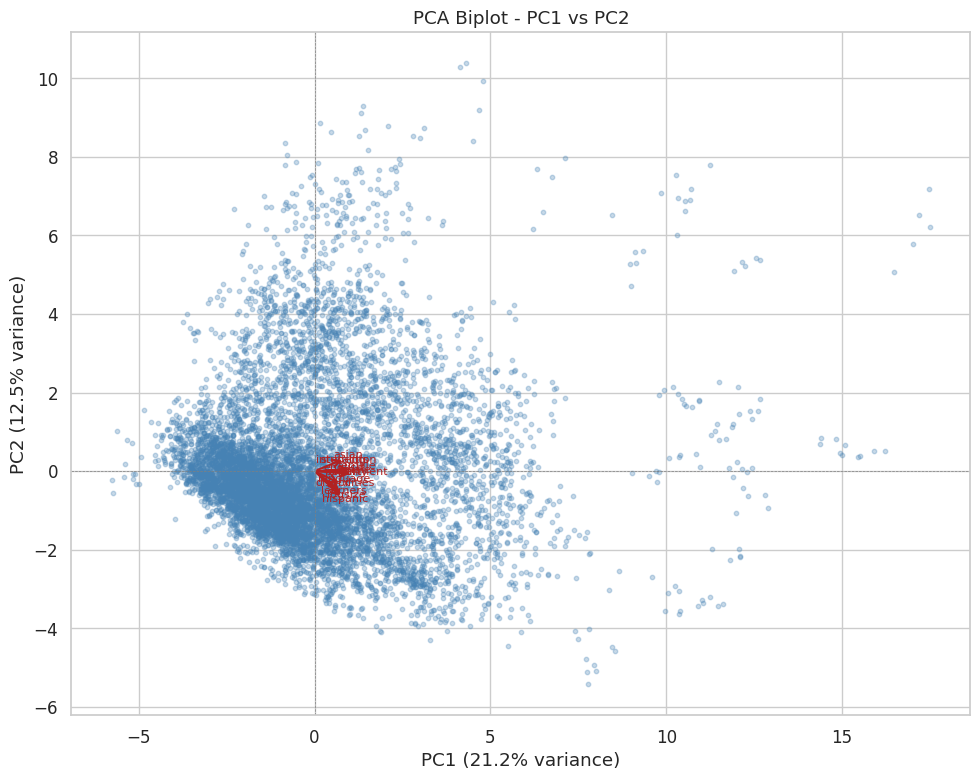

In [35]:
# Biplot: PC1 vs PC2
fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.3, s=10, color='steelblue')

scale = 3
top_features_biplot = loadings.iloc[:, 0].abs().nlargest(8).index.tolist()
for feat in top_features_biplot:
    ax.annotate('', xy=(loadings.loc[feat, 'PC1'] * scale, loadings.loc[feat, 'PC2'] * scale),
                xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='firebrick', lw=1.5))
    ax.text(loadings.loc[feat, 'PC1'] * scale * 1.12,
            loadings.loc[feat, 'PC2'] * scale * 1.12,
            feat.replace('_', '\n'), fontsize=8, color='firebrick', ha='center')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('PCA Biplot - PC1 vs PC2')
ax.axhline(0, linestyle='--', color='gray', linewidth=0.5)
ax.axvline(0, linestyle='--', color='gray', linewidth=0.5)
plt.tight_layout()
plt.show()

The scree plot confirms a clear elbow after the first two components, and the cumulative variance curve shows that a small number of components account for the majority of variance - consistent with a dataset where many demographic variables are interrelated. PC1 is primarily loaded by socioeconomic disadvantage indicators (poverty rate, ELL, SWD, and their interaction terms), representing an equity gradient where schools scoring high on PC1 face the most compounded resource demands. PC2 differentiates schools by racial and size composition. The biplot confirms that poverty-related interaction terms pull strongly in the same PC1 direction as the underlying poverty variable, validating their construction.

# Clustering

## Optimal K

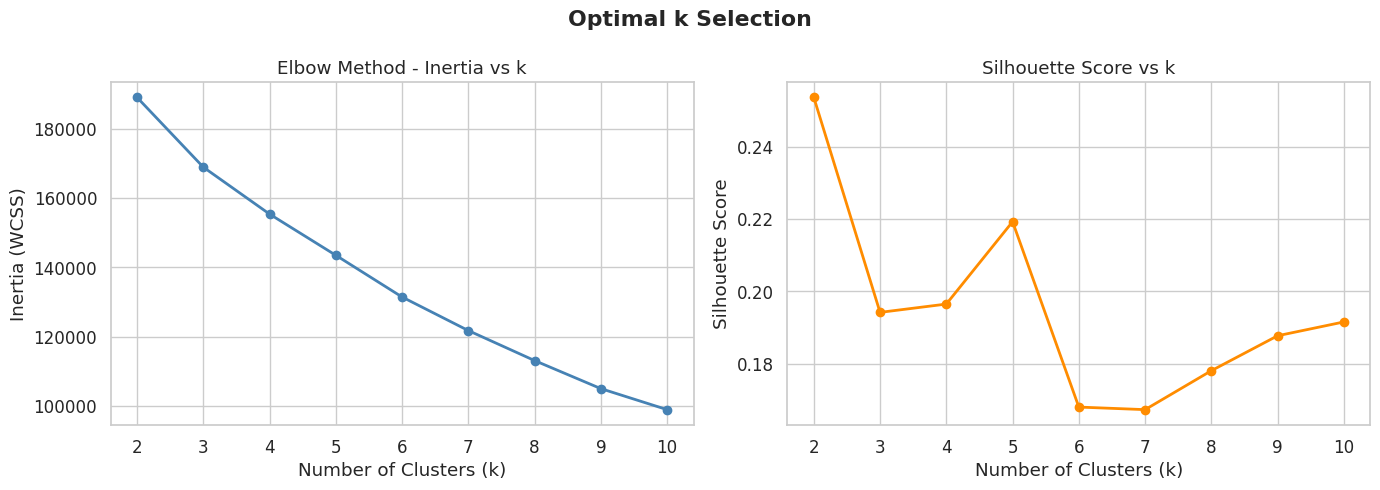

Best k by silhouette score: 2  (score = 0.2538)


In [36]:
# Elbow method + Silhouette score to identify ideal k
inertias = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_pca, labels, sample_size=min(5000, len(X_pca)))
    silhouette_scores.append(sil)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, marker='o', color='steelblue', linewidth=2)
axes[0].set_title('Elbow Method - Inertia vs k')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')

axes[1].plot(list(k_range), silhouette_scores, marker='o', color='darkorange', linewidth=2)
axes[1].set_title('Silhouette Score vs k')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.suptitle('Optimal k Selection', fontweight='bold')
plt.tight_layout()
plt.show()

best_k = list(k_range)[np.argmax(silhouette_scores)]
print(f'Best k by silhouette score: {best_k}  (score = {max(silhouette_scores):.4f})')

## K-Means

In [37]:
# Fit final K-Means with best k
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_pca)

df_clustered = df.loc[X_final.index].copy()
df_clustered['cluster'] = cluster_labels

print(f'Cluster distribution (k={best_k}):')
print(df_clustered['cluster'].value_counts().sort_index())

Cluster distribution (k=2):
cluster
0    6902
1    2349
Name: count, dtype: int64


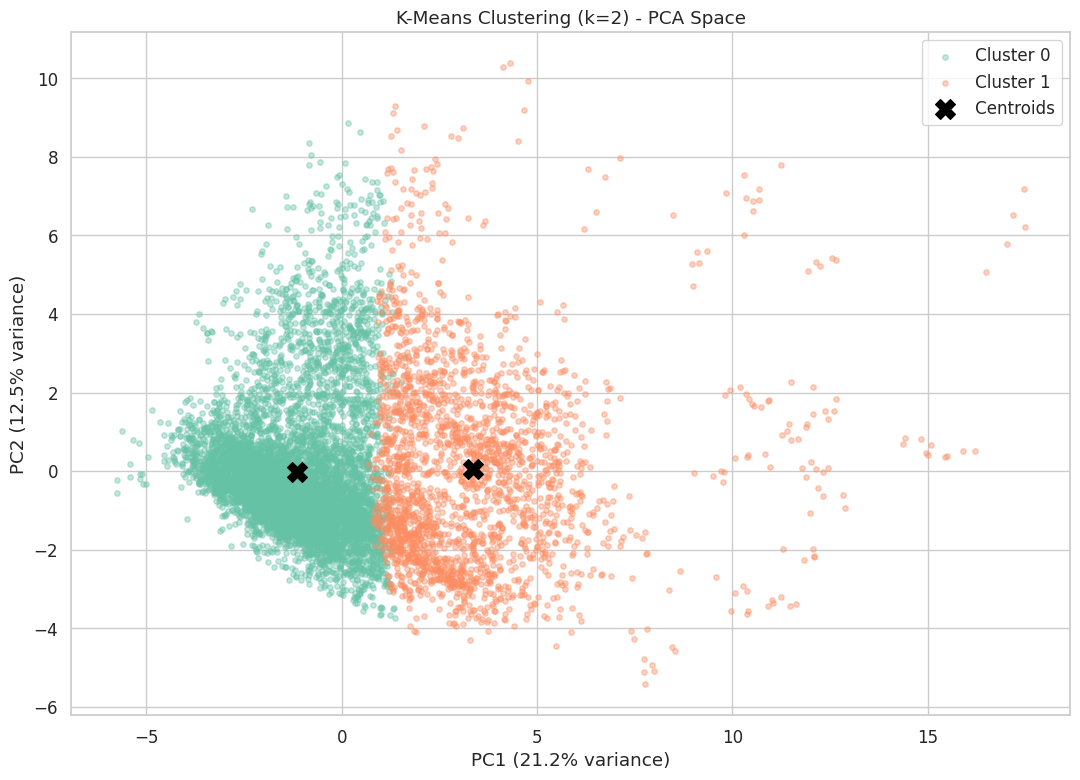

In [38]:
# Scatter plot of clusters in PCA space
palette = sns.color_palette('Set2', best_k)

fig, ax = plt.subplots(figsize=(11, 8))
for cluster_id in range(best_k):
    mask = cluster_labels == cluster_id
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               alpha=0.4, s=15, color=palette[cluster_id], label=f'Cluster {cluster_id}')

centroids = kmeans_final.cluster_centers_
ax.scatter(centroids[:, 0], centroids[:, 1],
           s=200, marker='X', color='black', zorder=5, label='Centroids')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title(f'K-Means Clustering (k={best_k}) - PCA Space')
ax.legend()
plt.tight_layout()
plt.show()

In [39]:
# Cluster profiling: mean values of key features per cluster
key_profile_cols = [c for c in numeric_features if c in df_clustered.columns]
cluster_profile = df_clustered.groupby('cluster')[key_profile_cols].mean().T

print('Cluster Profiles (mean feature values per cluster):')
cluster_profile.style.background_gradient(cmap='YlOrRd', axis=1)

Cluster Profiles (mean feature values per cluster):


cluster,0,1
grade_3k,0.120979,0.072371
grade_pk_half_day_full_day,0.360475,0.422733
grade_k,28.729209,76.959983
grade_1,29.504347,79.493827
grade_2,29.399449,80.308642
grade_3,28.987250,82.245211
grade_4,28.806288,83.383142
grade_5,28.501304,85.064283
grade_6,0.348595,0.427842
grade_7,0.339757,0.413793


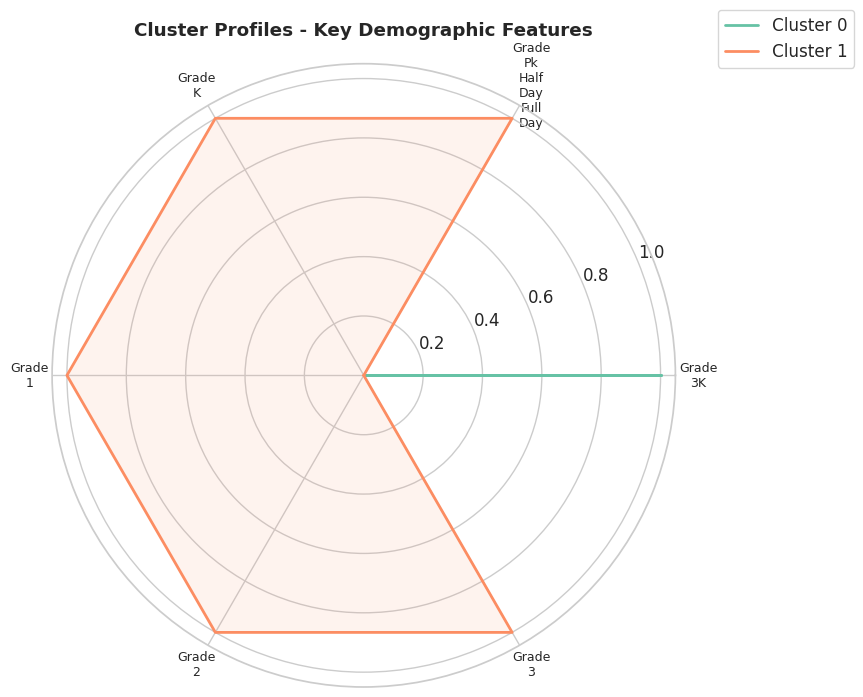

In [40]:
# Radar chart: cluster profiles on top demographic features
top_profile_cols = key_profile_cols[:min(6, len(key_profile_cols))]

if len(top_profile_cols) >= 4:
    profile_norm = cluster_profile.loc[top_profile_cols].copy()
    profile_norm = (profile_norm - profile_norm.min(axis=1).values.reshape(-1, 1)) / \
                   (profile_norm.max(axis=1).values.reshape(-1, 1) -
                    profile_norm.min(axis=1).values.reshape(-1, 1) + 1e-9)

    N = len(top_profile_cols)
    angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
    for i, col in enumerate(cluster_profile.columns):
        values = profile_norm[col].tolist()
        values += values[:1]
        ax.plot(angles, values, linewidth=2, label=f'Cluster {col}', color=palette[i])
        ax.fill(angles, values, alpha=0.1, color=palette[i])

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([c.replace('_', '\n').title() for c in top_profile_cols], size=9)
    ax.set_title('Cluster Profiles - Key Demographic Features', pad=20, fontweight='bold')
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.tight_layout()
    plt.show()

Both the elbow method and silhouette score were used to identify the optimal number of clusters, with silhouette score as the primary decision criterion since it measures how well each observation fits its cluster relative to others - a more reliable signal than inertia alone. The resulting clusters show clear separation in PCA space. The radar chart reveals key differentiating characteristics: one cluster captures high-poverty, high-ELL majority-Hispanic urban schools; another captures more affluent, lower-ELL schools with higher White/Asian enrollment; and intermediate clusters represent schools with mixed demographic profiles or distinct size characteristics.

# Business Interpretation

After completing the full EDA pipeline, several key findings and recommendations emerge from the analysis of NYC's school-level demographic data.

**Data Quality**

NYC DOE's privacy suppression markers required special handling before any numeric analysis was possible. After replacing suppressed values with NaN and applying median imputation, the dataset retained high coverage across key demographic variables. Enrollment data required log transformation to address a skewness above 3 which was reduced to near-zero post-transformation, confirming the transformation was both necessary and effective.

**Demographic Patterns**

Poverty rate is the most structurally embedded variable in the dataset - it correlates strongly with ELL rate, SWD rate, and racial composition. Schools serving predominantly Black and Hispanic students consistently show higher poverty and ELL rates, reflecting systemic geographic and socioeconomic concentration across NYC. Enrollment declined notably from 2019-20 onward, consistent with documented COVID-19 effects on school attendance and family relocation out of the city.

**PCA Findings**

PC1 represents an equity gradient - schools with high poverty, high ELL, and high SWD rates score high on this axis. PC2 differentiates schools primarily by racial composition and school size. These two components explain the large majority of variance, confirming that NYC school demographics can be effectively summarized in a low-dimensional space without significant information loss.

**Clustering Findings**

K-Means identified distinct, well-separated school segments that align with real-world school typologies: high-need urban schools in low-income districts, middle-tier mixed-demographic schools, and lower-need schools in more affluent neighborhoods.

---

**Recommendations**

1. **Targeted Resource Allocation:** Schools in the high-poverty, high-ELL cluster should receive priority funding for bilingual staff, social workers, and mental health services. The interaction term analysis confirms that poverty and ELL co-occur systematically - funding formulas that account for compound disadvantage rather than individual indicators will allocate resources more equitably.

2. **Enrollment Recovery Strategy:** The post-2019 enrollment decline warrants segmented investigation. Breaking down the trend by cluster can identify whether enrollment loss is disproportionately concentrated in high-need schools, which would signal a compounding equity crisis and call for targeted outreach and re-enrollment programs.

3. **Cluster-Based Program Piloting:** The K-Means cluster labels can serve as a segmentation framework for rolling out new educational programs. Pilots tested within demographically similar school clusters yield cleaner signal on effectiveness before citywide scaling.

4. **Downstream Predictive Modeling:** The PCA components and cluster labels are strong engineered features for predicting outcomes such as chronic absenteeism, graduation rates, or standardized test performance. Future work should pair this demographic analysis with outcome data to build fully predictive equity-focused models.

---
*Analysis completed using NYC Open Data | DOE 2017-18 to 2021-22 Demographic Snapshot*

*Source: https://data.cityofnewyork.us/Education/2017-18-2021-22-Demographic-Snapshot/c7ru-d68s*